In [5]:
import sys
from pathlib import Path

project_root = Path.cwd().parent
sys.path.append(str(project_root))

print(project_root)

c:\Users\Zafeer\MovieRecommendation


In [6]:
from src.data_collection import collect_movies

new_records = collect_movies(failed_ids)

print("Successfully collected:", len(new_records))

Checkpoint saved: 1 movies
Collected: The Departed
Checkpoint saved: 2 movies
Collected: The Day After Tomorrow
Checkpoint saved: 3 movies
Collected: Fantastic Mr. Fox
Checkpoint saved: 4 movies
Collected: Indiana Jones and the Kingdom of the Crystal Skull
Checkpoint saved: 5 movies
Collected: Bolt
Checkpoint saved: 6 movies
Collected: The Goonies
Checkpoint saved: 7 movies
Collected: Don't Look Up
Checkpoint saved: 8 movies
Collected: Signs
Checkpoint saved: 9 movies
Collected: Rambo: Last Blood
Checkpoint saved: 10 movies
Collected: Gran Torino
Checkpoint saved: 11 movies
Collected: Crimson Peak
Checkpoint saved: 12 movies
Collected: Day of the Woman
Checkpoint saved: 13 movies
Collected: The Pink Panther
Checkpoint saved: 14 movies
Collected: Osiris
Checkpoint saved: 15 movies
Collected: The Twilight Samurai
Checkpoint saved: 16 movies
Collected: In the Line of Fire
Checkpoint saved: 17 movies
Collected: Dial M for Murder
Checkpoint saved: 18 movies
Collected: Crocodile Dundee
Check

In [14]:
import json
from pathlib import Path

original_path = Path("../data/raw/movies_checkpoint.json")
new_path = Path("data/raw/movies_checkpoint.json")

with open(original_path, "r", encoding="utf-8") as f:
    original_movies = json.load(f)

with open(new_path, "r", encoding="utf-8") as f:
    new_movies = json.load(f)

# Keep original records and add only new movie IDs
existing_ids = {movie["movie_id"] for movie in original_movies}

for movie in new_movies:
    if movie["movie_id"] not in existing_ids:
        original_movies.append(movie)
        existing_ids.add(movie["movie_id"])

# Save merged records to the original checkpoint
with open(original_path, "w", encoding="utf-8") as f:
    json.dump(original_movies, f, indent=4, ensure_ascii=False)

print("Total merged movies:", len(original_movies))

Total merged movies: 4905


In [112]:
import json

with open("../data/raw/movie_ids.json", "r", encoding="utf-8") as f:
    movie_ids = json.load(f)

with open("../data/raw/movies_raw.json", "r", encoding="utf-8") as f:
    movies = json.load(f)

with open("../data/raw/failed_movie_ids.json", "r", encoding="utf-8") as f:
    failed_ids = json.load(f)

collected_ids = [movie["movie_id"] for movie in movies]

print("Total movie IDs:", len(movie_ids))
print("Collected records:", len(movies))
print("Unique collected IDs:", len(set(collected_ids)))
print("Failed IDs:", len(failed_ids))
print("Missing IDs:", len(set(movie_ids) - set(collected_ids)))

Total movie IDs: 4905
Collected records: 4905
Unique collected IDs: 4905
Failed IDs: 25
Missing IDs: 0


In [113]:
import json
import pandas as pd

with open("../data/raw/movies_raw.json", "r", encoding="utf-8") as file:
    movie_records = json.load(file)

movies_df = pd.DataFrame(movie_records)

print("Dataset shape:", movies_df.shape)
movies_df.head(10)

Dataset shape: (4905, 12)


,movie_id,title,overview,genres,release_date,runtime,vote_average,vote_count,popularity,cast,director,keywords
0,687163,Project Hail Mary,Science teacher Ryland Grace wakes up on a spa...,"[Science Fiction, Adventure]",2026-03-15,157,8.625,8903,323.1141,"[Ryan Gosling, Sandra Hüller, James Ortiz, Lio...","[Phil Lord, Christopher Miller]","[friendship, coma, based on novel or book, bra..."
1,1423191,Resident Evil,Medical courier Bryan unwittingly finds himsel...,"[Horror, Science Fiction, Adventure]",2026-09-16,94,7.524,2250,500.5989,"[Austin Abrams, Paul Walter Hauser, Kali Reis,...",[Zach Cregger],"[isolation, infection, outbreak, survival, dec..."
2,1263337,Heart of the Beast,"After a harrowing plane crash, Special Forces ...","[Adventure, Thriller]",2026-09-19,101,7.586,853,556.1351,"[Brad Pitt, J.K. Simmons, Anna Lambe, Justin M...",[David Ayer],"[alaska, dog, special forces, military, americ..."
3,155,The Dark Knight,Batman raises the stakes in his war on crime. ...,"[Action, Thriller, Crime]",2008-07-16,152,8.540,37393,74.4151,"[Christian Bale, Heath Ledger, Aaron Eckhart, ...",[Christopher Nolan],"[sadism, chaos, secret identity, crime fighter..."
4,1368337,The Odyssey,"Odysseus, the legendary King of Ithaca, embark...","[Adventure, Action, Fantasy]",2026-07-15,173,8.020,4923,485.6188,"[Matt Damon, Tom Holland, Anne Hathaway, Rober...",[Christopher Nolan],"[ship, trojan war, greek mythology, historical..."
5,550,Fight Club,A ticking-time-bomb insomniac and a slippery s...,"[Drama, Thriller]",1999-10-15,139,8.437,33350,35.2704,"[Edward Norton, Brad Pitt, Helena Bonham Carte...",[David Fincher],"[dual identity, rage and hate, based on novel ..."
6,27205,Inception,"Cobb, a skilled thief who commits corporate es...","[Action, Science Fiction, Crime]",2010-07-15,148,8.373,40748,47.2662,"[Leonardo DiCaprio, Joseph Gordon-Levitt, Ken ...",[Christopher Nolan],"[mission, dreams, kidnapping, spy, allegory, i..."
7,1400837,Other Mommy,7-year-old Bela forms a relationship with a si...,"[Horror, Mystery]",2026-10-07,93,6.296,432,399.9026,"[Jessica Chastain, Arabella Olivia Clark, Jay ...",[Rob Savage],"[based on novel or book, supernatural, haunted..."
8,656908,Ramayana: Rise of a Legend,An ancient epic follows a young prince and pri...,"[Fantasy, Action, Adventure]",2026-11-05,201,7.400,51,131.9195,"[Ranbir Kapoor, Yash, Sai Pallavi, Ravi Dubey,...",[Nitesh Tiwari],"[ramayana, based on myths, legends or folklore..."
9,299534,Avengers: Endgame,After the devastating events of Avengers: Infi...,"[Adventure, Science Fiction, Action]",2019-04-24,181,8.247,29335,84.7840,"[Robert Downey Jr., Chris Evans, Mark Ruffalo,...","[Anthony Russo, Joe Russo]","[superhero, time travel, space travel, time ma..."


In [114]:
print("Dataset shape:", movies_df.shape)

print("\nColumns:")
print(movies_df.columns.tolist())


Dataset shape: (4905, 12)

Columns:
['movie_id', 'title', 'overview', 'genres', 'release_date', 'runtime', 'vote_average', 'vote_count', 'popularity', 'cast', 'director', 'keywords']


In [115]:
print("Number of movies:", len(movies_df))
print("Duplicate movie IDs:", movies_df["movie_id"].duplicated().sum())
print("Missing values:\n", movies_df.isnull().sum())

Number of movies: 4905
Duplicate movie IDs: 0
Missing values:
 movie_id        0
title           0
overview        0
genres          0
release_date    0
runtime         0
vote_average    0
vote_count      0
popularity      0
cast            0
director        0
keywords        0
dtype: int64


In [116]:
movies_df.describe()

,movie_id,runtime,vote_average,vote_count,popularity
count,4.905000e+03,4905.000000,4905.000000,4905.000000,4905.000000
mean,4.200994e+05,109.551886,6.704625,3530.352090,9.485713
std,5.252736e+05,26.616120,1.257640,4584.387442,20.035668
min,5.000000e+00,0.000000,0.000000,0.000000,1.319600
25%,9.693000e+03,95.000000,6.299000,709.000000,4.309500
50%,1.096890e+05,108.000000,6.837000,2044.000000,5.699800
75%,7.262090e+05,123.000000,7.400000,4437.000000,8.838100
max,1.823907e+06,254.000000,10.000000,41913.000000,556.135100


runtime minimum = 0: Some records may have missing or unavailable runtime represented as zero.
Vote average minimum = 0: Some movies may not have received ratings.
Popularity maximum = 556.14: A few movies may be much more popular than most of the dataset.
Vote count maximum = 41,913: The dataset has movies with very different levels of audience engagement.

In [117]:
movies_df.isnull().sum()

movie_id        0
title           0
overview        0
genres          0
release_date    0
runtime         0
vote_average    0
vote_count      0
popularity      0
cast            0
director        0
keywords        0
dtype: int64

In [118]:
print("Zero runtime:", (movies_df["runtime"] == 0).sum())
print("Zero vote average:", (movies_df["vote_average"] == 0).sum())
print("Zero vote count:", (movies_df["vote_count"] == 0).sum())

Zero runtime: 49
Zero vote average: 93
Zero vote count: 93


In [119]:
zero_vote_movies = movies_df[(movies_df["vote_average"]==0)&(movies_df["vote_count"]==0)]

print("movies with both zero values :",len(zero_vote_movies))

display(
    zero_vote_movies[
        ["movie_id", "title", "vote_average", "vote_count"]
    ].head(100)
)

movies with both zero values : 93


,movie_id,title,vote_average,vote_count
34,1003596,Avengers: Doomsday,0.0,0
76,1673439,Red Days 2: Cecilia,0.0,0
104,1310458,Saayavanam,0.0,0
113,1766192,Insidious Rewind,0.0,0
115,1327835,Mookuthi Amman 2,0.0,0
...,...,...,...,...
4630,1599184,Battle Through the Heavens Movie：Duel of the T...,0.0,0
4662,1135851,Keramat Tunggak Part 2,0.0,0
4709,1720486,Lilo & Scratch,0.0,0
4756,1748499,Kiku Chiranjeevi,0.0,0


In [120]:
zero_runtime_movies = movies_df[movies_df["runtime"] == 0]
print("number of movies with zero run time:",len(zero_runtime_movies))
display(
    zero_runtime_movies[
        ["movie_id", "title", "runtime"]
    ].head(10)
)

number of movies with zero run time: 49


,movie_id,title,runtime
84,1757324,Insecta,0
195,1651992,HATERNET,0
357,1669057,Check-In,0
397,1406492,La venganza del Charro Negro,0
703,1260649,Jumanji: Open World,0
710,1822701,El Marqués del SEPE,0
916,1497464,Gatto,0
962,1401586,Sonic the Hedgehog 4,0
995,1600653,The 12 Dates of Christmas,0
1028,1003598,Avengers: Secret Wars,0


In [121]:
print((movies_df["vote_average"]==0).sum())
print((movies_df["vote_count"]==0).sum())

93
93


In [122]:
print("Missing release dates:",
      movies_df["release_date"].isnull().sum())

print("Empty release dates:",
      (movies_df["release_date"] == "").sum())

Missing release dates: 0
Empty release dates: 2


In [123]:
movies_df["release_date"] = pd.to_datetime(
    movies_df["release_date"],
    errors="coerce"
)

print("Invalid or missing dates:",
      movies_df["release_date"].isnull().sum())

Invalid or missing dates: 2


In [124]:
movies_df[
    movies_df["release_date"].isnull()
][
    ["movie_id", "title", "release_date", "runtime",
     "vote_average", "vote_count", "genres"]
]

,movie_id,title,release_date,runtime,vote_average,vote_count,genres
113,1766192,Insidious Rewind,NaT,79,0.0,0,[Horror]
1072,1584720,Recep Ivedik 8,NaT,0,0.0,0,[Comedy]


In [125]:
print("Duplicate movie IDs:",
      movies_df["movie_id"].duplicated().sum())

Duplicate movie IDs: 0


In [126]:
import pandas as pd

# 1. Flatten all genres into a single standard Python list
all_genres = [
    genre
    for genres in movies_df["genres"]
    if isinstance(genres, list)
    for genre in genres
]

# 2. Put it into a Series, count, and reset index
genre_df = (
    pd.Series(all_genres)
    .value_counts()
    .reset_index()
)

genre_df.columns = ["Genre", "Movie_Count"]

display(genre_df)

,Genre,Movie_Count
0,Drama,1833
1,Action,1507
2,Comedy,1449
3,Thriller,1320
4,Adventure,1126
5,Science Fiction,739
6,Crime,736
7,Fantasy,721
8,Horror,711
9,Family,710


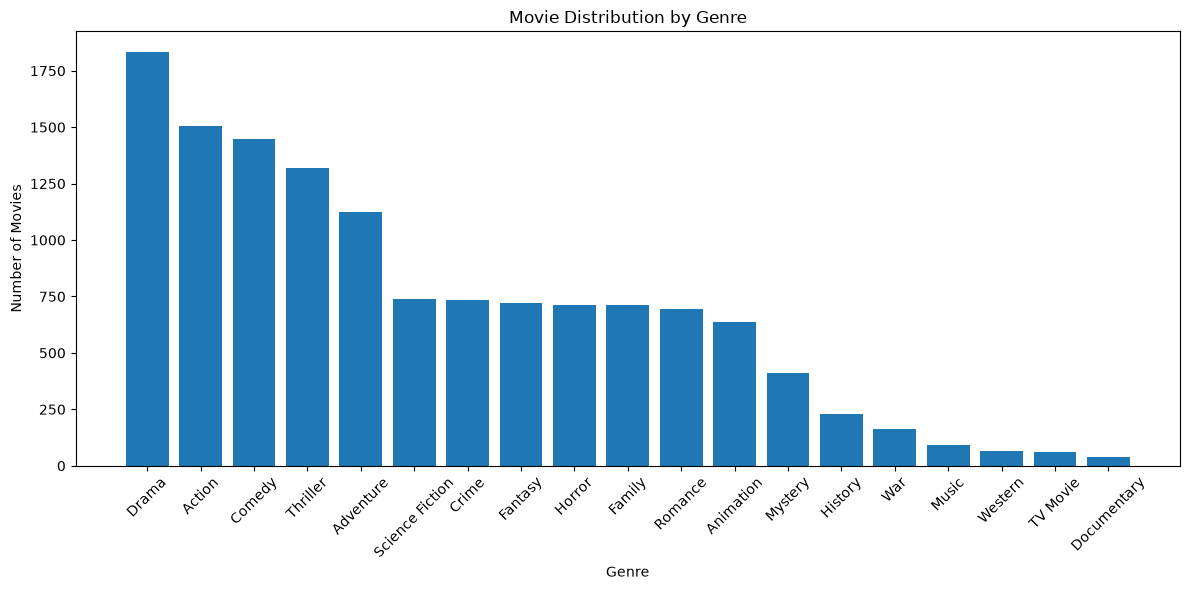

In [127]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.bar(
    genre_df["Genre"],
    genre_df["Movie_Count"]
)

plt.title("Movie Distribution by Genre")
plt.xlabel("Genre")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Drama is the most common genre (1,833 movies).

Action, Comedy and Thriller also have substantial representation.

Documentary and TV Movie have relatively few records.

The dataset has more mainstream entertainment genres than documentary content.

In [128]:
movies_df["genre_count"] = movies_df["genres"].apply(
    lambda x: len(x) if isinstance(x, list) else 0
)

print(movies_df["genre_count"].value_counts().sort_index())

genre_count
0       4
1     547
2    1433
3    2113
4     575
5     208
6      23
7       2
Name: count, dtype: int64


Three genres dominate: 2,113 movies have exactly three genres.

Multiple genres are common: 4,354 movies have at least two genres.

Only 547 movies have one genre.

Four movies have no genre information.

In [129]:
text_columns = ["overview", "genres", "cast", "director", "keywords"]

for col in text_columns:
    missing = movies_df[col].apply(
        lambda x: (
            pd.isna(x) if not isinstance(x, list) else len(x) == 0
        )
    ).sum()

    print(f"{col}: {missing}")

overview: 0
genres: 4
cast: 11
director: 16
keywords: 164


In [130]:
content_columns = ["overview", "genres", "cast", "director", "keywords"]

def is_missing_content(value):
    if isinstance(value, list):
        return len(value) == 0
    return pd.isna(value) or value == ""

movies_df["missing_feature_count"] = movies_df[
    content_columns
].apply(
    lambda row: sum(is_missing_content(value) for value in row),
    axis=1
)

print(movies_df["missing_feature_count"].value_counts().sort_index())

missing_feature_count
0    4730
1     155
2       9
3       8
4       3
Name: count, dtype: int64


In [131]:
incomplete_movies = movies_df[
    movies_df["missing_feature_count"] > 0
]

display(
    incomplete_movies[
        ["title", "overview", "genres", "cast",
         "director", "keywords", "missing_feature_count"]
    ].head(10)
)

,title,overview,genres,cast,director,keywords,missing_feature_count
22,Savage Prey,"In the remote Scottish Highlands, a desperate ...",[Thriller],"[Marta Svetek, Steve Weston, Ryan Livingstone,...",[David Ryan Keith],[],1
23,Robotica,Two security guards working the midnight shift...,"[Horror, Science Fiction]","[Lilly Bell, Ian Kramer, Steve Crawford, Micha...",[Charles Band],[],1
64,Tad and The Magic Lamp,"Tadeo, his girlfriend Sara, and his friends Mo...","[Animation, Comedy, Family]","[Óscar Barberán, Michelle Jenner, Luis Posada,...",[Enrique Gato],[],1
76,Red Days 2: Cecilia,"Following the path of Cecilia, from Red Days, ...","[Action, Horror, Thriller]","[Melissa Dawn Smith, Lisa Butala, Nicole Mattox]",[Brett William Mauser],[],1
83,The Florist,A quiet horticulturalist harboring a secret li...,"[Action, Thriller]","[Dennis Quaid, Jean Reno, Sky Katz, Jim Klock,...",[Babak Najafi],[],1
84,Insecta,A celebrated horror novelist returns to an iso...,[Horror],"[Mayra Hermosillo, Rocío de la Mañana, Luis Fe...",[Martín Florio],[],1
92,The Good Lawyer,"After a courtroom overdose lands him in rehab,...","[Thriller, Drama]","[Laurent Lafitte, Anthony Bajon, Mélanie Laure...",[Tristan Séguéla],[],1
102,The Legend of the Black Charro,"After releasing the Chupacabras, Leo San Juan ...","[Animation, Fantasy, Action, Family]","[Benny Emmanuel, Annie Rojas, Emilio Treviño, ...",[Alberto Rodríguez],[],1
104,Saayavanam,Sita tries to live an honest and truthful life...,"[Thriller, Drama]","[Santhosh Damodharan, Soundara Raja, Devananda...",[Anil Kumar],[],1
115,Mookuthi Amman 2,"A queen sacrifices herself to protect her son,...","[Fantasy, Drama, Comedy]","[Nayanthara, Urvashi, Regena Cassandrra, Yogi ...",[Sundar C],[],1


In [132]:
display(
    movies_df[
        movies_df["missing_feature_count"] >= 2
    ][
        ["title", "overview", "genres",
         "cast", "director", "keywords",
         "missing_feature_count"]
    ]
)

,title,overview,genres,cast,director,keywords,missing_feature_count
215,Movida,Children play war between the abandoned houses...,[],[],[Alessandro Padovani],[],3
238,A Very Arctic Christmas,"Single dad Jim and his spirited, science-minde...","[TV Movie, Comedy, Romance]","[Cameron Mathison, Maya Skabar, Jill Wagner]",[],[],2
366,XXXXXXX,A tarot card reading as a starting point. A d...,[Documentary],[],[Liliana Colombo],[],2
710,El Marqués del SEPE,,"[Comedy, Fantasy]",[],[],[],4
1252,Paranorías: The Lost Files of Dr. Romanoski,"While researching in a psychiatric hospital, D...",[Comedy],[],[Matías Carelli],[],2
2200,Three Too Many,,[Comedy],"[Kira Miró, Salva Reina, Luna Fulgencio, Ian C...",[Mar Olid],[],2
2292,GGS - Ganteng-Ganteng Sange,Kelas Bintang is back with this pack of drama ...,"[Drama, Romance]",[],[],[],3
2379,Cars: Spooky Halloween Adventure,"It's Halloween night in Radiator Springs, and ...","[Animation, Family]",[],[],[],3
2462,Rafadan Tayfa: Gordion,,"[Animation, Family]","[Hakan Coşar, Yağmur Sergen, Levent Kol, Şirin...",[],[],3
2676,Supernatural Academy: Fate of the Dragon King,,"[Animation, Fantasy, Adventure]","[Larissa Dias, Gigi Saul Guerrero, Cardi Wong,...",[Steve Ball],[],2


In [133]:
movies_df[
    ["runtime", "vote_average", "vote_count", "popularity"]
].describe()

,runtime,vote_average,vote_count,popularity
count,4905.000000,4905.000000,4905.000000,4905.000000
mean,109.551886,6.704625,3530.352090,9.485713
std,26.616120,1.257640,4584.387442,20.035668
min,0.000000,0.000000,0.000000,1.319600
25%,95.000000,6.299000,709.000000,4.309500
50%,108.000000,6.837000,2044.000000,5.699800
75%,123.000000,7.400000,4437.000000,8.838100
max,254.000000,10.000000,41913.000000,556.135100


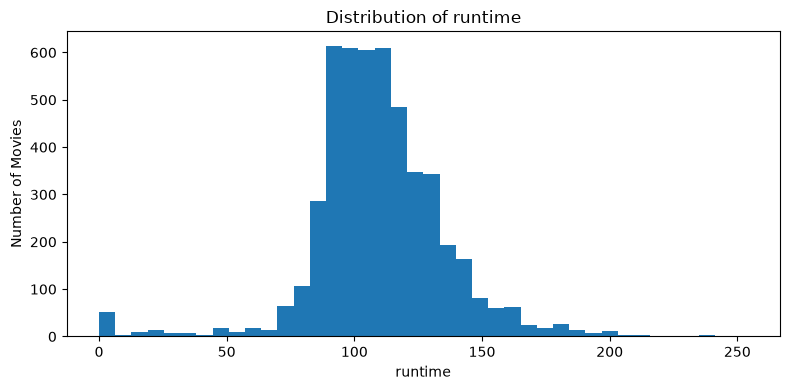

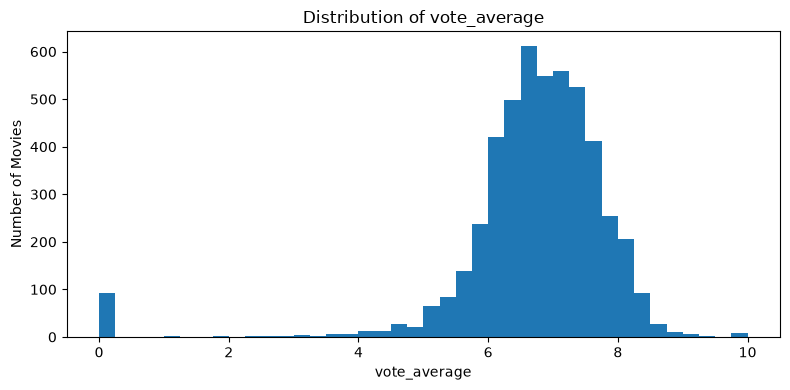

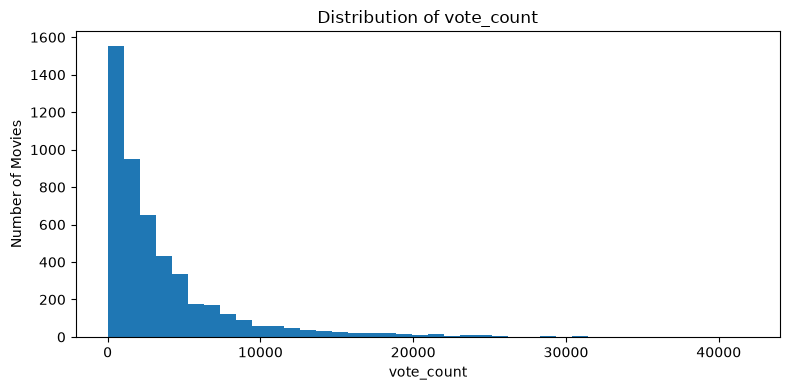

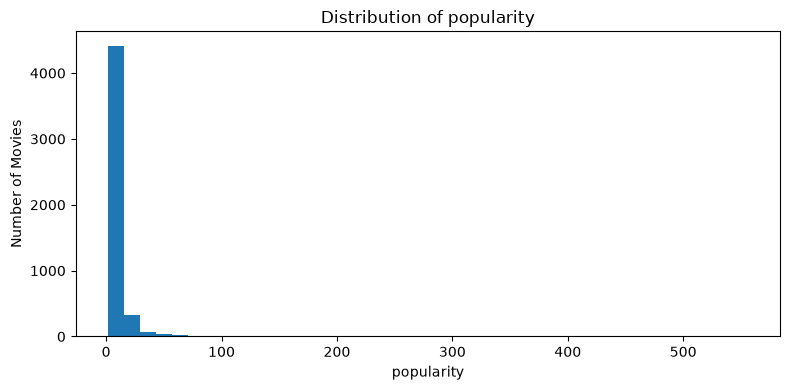

In [134]:
import matplotlib.pyplot as plt

numerical_columns = [
    "runtime",
    "vote_average",
    "vote_count",
    "popularity"
]

for col in numerical_columns:
    plt.figure(figsize=(8, 4))

    plt.hist(movies_df[col], bins=40)

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Number of Movies")

    plt.tight_layout()
    plt.show()

**NUMERICAL FEATURES OBSERVATION**

Runtime: Most movies are around 100–110 minutes. Some unusually short and long movies exist.



Vote average: Most ratings are concentrated around 6–7.5.



Vote count: Highly right-skewed. A small number of movies receive significantly more votes.



Popularity: Also highly right-skewed, with a few movies having exceptionally high popularity.



Outliers were identified, but they should not automatically be removed because they may represent genuine movies.

In [135]:
for col in numerical_columns:
    Q1 = movies_df[col].quantile(0.25)
    Q3 = movies_df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = movies_df[
        (movies_df[col] < lower) |
        (movies_df[col] > upper)
    ]

    print(f"\n{col}")
    print("Lower bound:", lower)
    print("Upper bound:", upper)
    print("Outlier count:", len(outliers))


runtime
Lower bound: 53.0
Upper bound: 165.0
Outlier count: 239

vote_average
Lower bound: 4.647500000000001
Upper bound: 9.0515
Outlier count: 181

vote_count
Lower bound: -4883.0
Upper bound: 10029.0
Outlier count: 382

popularity
Lower bound: -2.4834000000000014
Upper bound: 15.631000000000002
Outlier count: 465


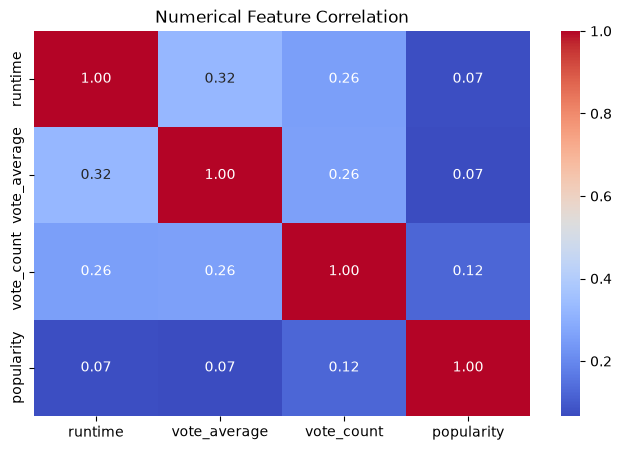

In [136]:
correlation = movies_df[
    ["runtime", "vote_average", "vote_count", "popularity"]
].corr()

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Numerical Feature Correlation")
plt.show()

In [137]:
print(correlation)

               runtime  vote_average  vote_count  popularity
runtime       1.000000      0.324649    0.256483    0.072550
vote_average  0.324649      1.000000    0.259803    0.066988
vote_count    0.256483      0.259803    1.000000    0.123377
popularity    0.072550      0.066988    0.123377    1.000000


In [138]:
movies_df["release_year"] = movies_df["release_date"].dt.year

print(movies_df["release_year"].describe())

count    4903.000000
mean     2008.908016
std        16.771118
min      1922.000000
25%      2001.000000
50%      2013.000000
75%      2023.000000
max      2028.000000
Name: release_year, dtype: float64


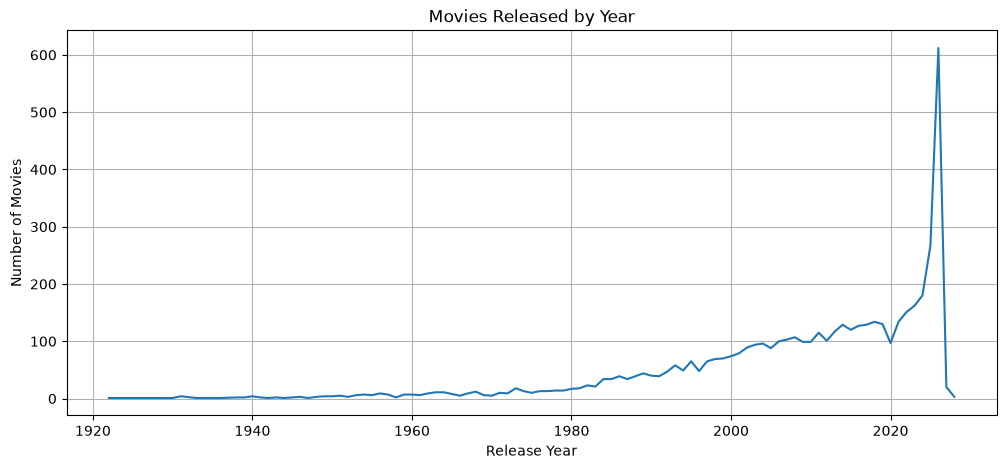

In [139]:
year_counts = movies_df["release_year"].value_counts().sort_index()

plt.figure(figsize=(12, 5))
plt.plot(year_counts.index, year_counts.values)

plt.title("Movies Released by Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Movies")
plt.grid()
plt.show()

The dataset contains movies released across several decades.



Recent years have considerably more records than older decades.



There is a noticeable increase in 2025 and 2026 records.



Upcoming movies are also present, so release status must be considered when building recommendations.

In [157]:
print(
    movies_df["release_year"]
    .value_counts()
    .sort_index()
    .tail(10)
)

release_year
2019.0    130
2020.0     97
2021.0    134
2022.0    151
2023.0    162
2024.0    180
2025.0    267
2026.0    612
2027.0     20
2028.0      3
Name: count, dtype: int64


In [154]:
today = pd.Timestamp.today().normalize()

upcoming_movies = movies[
    movies["release_date"].notna()
    & (movies["release_date"] >= today)
]

In [158]:
display(upcoming_movies)

,movie_id,title,overview,genres,release_date,runtime,vote_average,vote_count,popularity,cast,director,keywords,genre_count,missing_feature_count,release_year
34,1003596,Avengers: Doomsday,Beloved heroes from three distinct universes a...,"[Science Fiction, Action, Adventure]",2026-12-16,165,0.000,0,162.9279,"[Robert Downey Jr., Chris Evans, Chris Hemswor...","[Joe Russo, Anthony Russo]","[superhero, based on comic, sequel, superhero ...",3,0,2026.0
48,1300968,The Hunger Games: Sunrise on the Reaping,Return to the world of Panem 24 years before t...,"[Science Fiction, Action, Adventure]",2026-11-18,159,9.357,7,65.0820,"[Joseph Zada, Mckenna Grace, Ralph Fiennes, Je...",[Francis Lawrence],"[based on novel or book, dystopia, post-apocal...",3,0,2026.0
200,1170608,Dune: Part Three,Nearly two decades after he seized control of ...,"[Science Fiction, Adventure]",2026-12-15,150,0.000,0,27.3440,"[Timothée Chalamet, Zendaya, Jason Momoa, Flor...",[Denis Villeneuve],"[based on novel or book, religious war, sequel...",2,0,2026.0
341,1538497,Hexed,An impulsive and unconventional teenage girl n...,"[Adventure, Animation, Family, Fantasy, Comedy]",2026-11-25,103,0.000,0,19.7942,"[Hailee Steinfeld, Rashida Jones, Jodie Foster...","[Jason Hand, Fawn Veerasunthorn]","[witch, magic, teenage girl, mother daughter r...",5,0,2026.0
517,1400336,Focker-in-Law,"Henry, son of Greg and Pam Focker, aims to mar...","[Comedy, Romance]",2026-11-21,105,0.000,0,16.1296,"[Ben Stiller, Robert De Niro, Ariana Grande, S...",[John Hamburg],"[romcom, family relationships, sequel, overbea...",2,0,2026.0
703,1260649,Jumanji: Open World,Our heroes have escaped the ever-changing jung...,"[Adventure, Comedy, Fantasy]",2026-12-23,0,0.000,0,12.8221,"[Dwayne Johnson, Kevin Hart, Jack Black, Karen...",[Jake Kasdan],"[based on novel or book, video game, winter, s...",3,0,2026.0
916,1497464,Gatto,"After years of maneuvering the canal-ridden, s...","[Animation, Comedy, Crime, Family, Adventure]",2027-03-03,0,0.000,0,10.8953,"[Mark Ruffalo, Laurence Fishburne, Enrico Casa...",[Enrico Casarosa],"[friendship, venice, italy, cat, italy, supers...",5,0,2027.0
922,1457866,THE FURTHER MIS-ADVENTURES OF CLIFF BOOTH,Eight years after the events of Once Upon a Ti...,"[Comedy, Drama, Thriller]",2026-11-25,141,0.000,0,10.1117,"[Brad Pitt, Elizabeth Debicki, Scott Caan, Yah...",[David Fincher],"[1970s, dark comedy, sequel, film noir, hollyw...",3,0,2026.0
962,1401586,Sonic the Hedgehog 4,The fourth installment in the Sonic the Hedgeh...,"[Comedy, Action, Family, Science Fiction]",2027-03-11,0,0.000,0,9.7888,"[Ben Schwartz, Jim Carrey, Kristen Bell, Idris...",[Jeff Fowler],"[time travel, sequel, romance, dinosaur, based...",4,0,2027.0
1028,1003598,Avengers: Secret Wars,An upcoming film in Phase Six of the Marvel Ci...,"[Science Fiction, Action, Adventure]",2027-12-15,0,0.000,0,10.1133,"[Robert Downey Jr., Pedro Pascal, Vanessa Kirb...","[Joe Russo, Anthony Russo]","[superhero, based on comic, sequel, superhero ...",3,0,2027.0


In [155]:
print(len(upcoming_movies))

56


There are 56 movies upcoming from the day of doing the EDA, so there would be some missing feature details 

In [143]:
all_directors = [
    director
    for directors in movies_df["director"]
    if isinstance(directors, list)
    for director in directors
]

top_directors = (
    pd.Series(all_directors)
    .value_counts()
    .head(15)
    .reset_index()
)

top_directors.columns = ["Director", "Movie_Count"]
print(top_directors)

              Director  Movie_Count
0     Steven Spielberg           31
1         Ridley Scott           22
2      Martin Scorsese           19
3           Ron Howard           19
4       Clint Eastwood           19
5      Robert Zemeckis           18
6           Tim Burton           17
7     Robert Rodriguez           15
8        Antoine Fuqua           14
9          Guy Ritchie           14
10  M. Night Shyamalan           13
11         Michael Bay           13
12   Christopher Nolan           12
13       David Fincher           12
14      Hayao Miyazaki           12


The top directors have multiple movies in the dataset.


Steven Spielberg appears most by 31 movies.


Christopher Nolan appears 12 times.


The distribution is not dominated by a single director.

In [144]:
all_cast = [
    actor
    for cast_members in movies_df["cast"]
    if isinstance(cast_members, list)
    for actor in cast_members
]

top_cast = (
    pd.Series(all_cast)
    .value_counts()
    .head(15)
    .reset_index()
)

top_cast.columns = ["Actor", "Movie_Count"]

print(top_cast)

                 Actor  Movie_Count
0       Robert De Niro           44
1            Tom Hanks           41
2    Samuel L. Jackson           41
3         Nicolas Cage           41
4            Brad Pitt           39
5        Jason Statham           39
6        Mark Wahlberg           37
7          Johnny Depp           35
8   Sylvester Stallone           35
9           Tom Cruise           35
10        Willem Dafoe           35
11         Jackie Chan           33
12          Matt Damon           32
13       Harrison Ford           32
14         Liam Neeson           31


Several actors appear frequently across the collected movies.

collected only the top 5 cast members per movie, these counts represent appearances among those five, not the actor's complete filmography.

In [145]:
all_keywords = [
    keyword
    for keywords in movies_df["keywords"]
    if isinstance(keywords, list)
    for keyword in keywords
]

top_keywords = (
    pd.Series(all_keywords)
    .value_counts()
    .head(20)
    .reset_index()
)

top_keywords.columns = ["Keyword", "Movie_Count"]

print(top_keywords)

                   Keyword  Movie_Count
0   based on novel or book          769
1                   sequel          703
2     duringcreditsstinger          373
3      aftercreditsstinger          306
4                   murder          290
5             3d animation          274
6      based on true story          268
7            new york city          239
8                  revenge          206
9           based on comic          205
10                 villain          203
11                  amused          194
12               superhero          189
13              friendship          186
14          woman director          184
15                  remake          179
16               halloween          176
17            martial arts          173
18                dystopia          172
19                 intense          165


Most of the popular films are either based on novel or book category 

sequel movies also show greater impact


Drama, Action and Comedy are among the most frequent genres.



Steven Spielberg is the most frequently appearing director in the dataset.



Robert De Niro is the most frequent actor among the collected top-five cast members.



Keywords such as based on novel or book, sequel, murder and revenge describe themes and characteristics that genres alone cannot capture.



Some movies have incomplete content features, particularly keywords.

In [146]:
movies = movies_df.copy()

movies.info()

<class 'pandas.DataFrame'>
RangeIndex: 4905 entries, 0 to 4904
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   movie_id               4905 non-null   int64         
 1   title                  4905 non-null   str           
 2   overview               4905 non-null   str           
 3   genres                 4905 non-null   object        
 4   release_date           4903 non-null   datetime64[us]
 5   runtime                4905 non-null   int64         
 6   vote_average           4905 non-null   float64       
 7   vote_count             4905 non-null   int64         
 8   popularity             4905 non-null   float64       
 9   cast                   4905 non-null   object        
 10  director               4905 non-null   object        
 11  keywords               4905 non-null   object        
 12  genre_count            4905 non-null   int64         
 13  missing_featur

In [156]:
movies.drop(
    columns=[
        "genre_count",
        "missing_feature_count",
        "release_year"
    ],
    inplace=True
)

movies.shape

(4905, 12)

In [159]:
import numpy as np

movies["runtime"] = movies["runtime"].replace(0, np.nan)

movies["runtime"].isna().sum()

np.int64(49)

In [161]:
print(movies[["vote_average", "vote_count"]].describe())

       vote_average    vote_count
count   4905.000000   4905.000000
mean       6.704625   3530.352090
std        1.257640   4584.387442
min        0.000000      0.000000
25%        6.299000    709.000000
50%        6.837000   2044.000000
75%        7.400000   4437.000000
max       10.000000  41913.000000


CLEANED CONVERSION


In [215]:
import importlib
import src.preprocessing

importlib.reload(src.preprocessing)

from src.preprocessing import clean_movie_data

movies_cleaned = clean_movie_data(movies_df)

print("Validation passed!")
print("Final shape:", movies_cleaned.shape)

Validation passed!
Final shape: (4905, 12)


In [24]:
from pathlib import Path

output_path = Path("../data/processed")
output_path.mkdir(parents=True, exist_ok=True)

movies_cleaned.to_csv(
    output_path / "movies_processed.csv",
    index=False
)

print("Processed dataset saved successfully!")

Processed dataset saved successfully!


In [25]:
from src.feature_engineering import combine_movie_features

sample_movie = movies_cleaned.iloc[0]

combined_text = combine_movie_features(sample_movie)

print(combined_text)

Science teacher Ryland Grace wakes up on a spaceship light years from home with no recollection of who he is or how he got there. As his memory returns, he begins to uncover his mission: solve the riddle of the mysterious substance causing the sun to die out. He must call on his scientific knowledge and unorthodox ideas to save everything on Earth from extinction. [ ' S c i e n c e   F i c t i o n ' ,   ' A d v e n t u r e ' ] [ ' f r i e n d s h i p ' ,   ' c o m a ' ,   ' b a s e d   o n   n o v e l   o r   b o o k ' ,   ' b r a v e r y ' ,   ' s u n ' ,   ' l a n g u a g e   b a r r i e r ' ,   ' s p a c e   t r a v e l ' ,   ' s p a c e   m i s s i o n ' ,   ' a l i e n ' ,   ' s p a c e ' ,   ' m e m o r y   l o s s ' ,   ' s u i c i d e   m i s s i o n ' ,   ' a s t r o n a u t ' ,   ' s c i e n t i s t ' ,   ' s c i e n c e   t e a c h e r ' ,   ' s a v e   t h e   p l a n e t ' ,   ' s p a c e s h i p ' ,   ' i n t e r s p e c i e s   f r i e n d s h i p ' ] [ ' R y a n   G o s

FEATURE ENGINEERING CONVERSION


In [28]:
import json
import pandas as pd

with open("../data/raw/movies_raw.json", "r", encoding="utf-8") as file:
    movies_data = json.load(file)

movies_df = pd.DataFrame(movies_data)

In [30]:
import importlib
import src.feature_engineering

importlib.reload(src.feature_engineering)

from src.feature_engineering import create_combined_features

movies_featured = create_combined_features(movies_cleaned)

print("Shape:", movies_featured.shape)
print("Missing features:", movies_featured["combined_features"].isna().sum())

Shape: (4905, 13)
Missing features: 0


In [201]:
movies_featured

,movie_id,title,overview,genres,release_date,runtime,vote_average,vote_count,popularity,cast,director,keywords,combined_features
0,687163,Project Hail Mary,Science teacher Ryland Grace wakes up on a spa...,"[Science Fiction, Adventure]",2026-03-15,157,8.625,8903,323.1141,"[Ryan Gosling, Sandra Hüller, James Ortiz, Lio...","[Phil Lord, Christopher Miller]","[friendship, coma, based on novel or book, bra...",Science teacher Ryland Grace wakes up on a spa...
1,1423191,Resident Evil,Medical courier Bryan unwittingly finds himsel...,"[Horror, Science Fiction, Adventure]",2026-09-16,94,7.524,2250,500.5989,"[Austin Abrams, Paul Walter Hauser, Kali Reis,...",[Zach Cregger],"[isolation, infection, outbreak, survival, dec...",Medical courier Bryan unwittingly finds himsel...
2,1263337,Heart of the Beast,"After a harrowing plane crash, Special Forces ...","[Adventure, Thriller]",2026-09-19,101,7.586,853,556.1351,"[Brad Pitt, J.K. Simmons, Anna Lambe, Justin M...",[David Ayer],"[alaska, dog, special forces, military, americ...","After a harrowing plane crash, Special Forces ..."
3,155,The Dark Knight,Batman raises the stakes in his war on crime. ...,"[Action, Thriller, Crime]",2008-07-16,152,8.54,37393,74.4151,"[Christian Bale, Heath Ledger, Aaron Eckhart, ...",[Christopher Nolan],"[sadism, chaos, secret identity, crime fighter...",Batman raises the stakes in his war on crime. ...
4,1368337,The Odyssey,"Odysseus, the legendary King of Ithaca, embark...","[Adventure, Action, Fantasy]",2026-07-15,173,8.02,4923,485.6188,"[Matt Damon, Tom Holland, Anne Hathaway, Rober...",[Christopher Nolan],"[ship, trojan war, greek mythology, historical...","Odysseus, the legendary King of Ithaca, embark..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4900,16962,Barbie Fairytopia: Magic of the Rainbow,Elina goes to a fairy school to learn dancing ...,"[Animation, Family, Fantasy, Romance]",2007-03-13,75,6.888,480,3.7617,"[Kelly Sheridan, Lee Tockar, Kathleen Barr, Ch...",[William Lau],"[magic, fairy, based on toy, female protagonis...",Elina goes to a fairy school to learn dancing ...
4901,9433,The Edge,The plane carrying wealthy Charles Morse crash...,"[Action, Adventure, Drama]",1997-09-06,117,6.893,1406,5.8434,"[Anthony Hopkins, Alec Baldwin, Elle Macpherso...",[Lee Tamahori],"[rescue, airplane, photographer, grizzly bear,...",The plane carrying wealthy Charles Morse crash...
4902,49730,Red Riding Hood,"Valerie is in love with a brooding outsider, P...","[Mystery, Fantasy, Horror, Thriller]",2011-03-10,100,5.973,3392,3.6799,"[Amanda Seyfried, Gary Oldman, Billy Burke, Sh...",[Catherine Hardwicke],"[winter, fairy tale, little red riding hood, h...","Valerie is in love with a brooding outsider, P..."
4903,376570,Hush,A deaf woman is stalked by a psychotic killer ...,"[Horror, Thriller]",2016-03-12,82,6.724,5023,3.8655,"[John Gallagher Jr., Kate Siegel, Michael Truc...",[Mike Flanagan],"[computer, isolation, deaf-mute, deaf, knife, ...",A deaf woman is stalked by a psychotic killer ...


CONTENT MODEL CONVERSION


In [32]:
from src.content_model import build_tfidf_matrix

vectorizer, tfidf_matrix = build_tfidf_matrix(movies_featured)

print("TF-IDF shape:", tfidf_matrix.shape)
print("Vocabulary size:", len(vectorizer.vocabulary_))

TF-IDF shape: (4905, 32913)
Vocabulary size: 32913


In [35]:
from src.content_model import recommend_movies

selected_movie_id = 687163

recommendations = recommend_movies(
    movie_id=selected_movie_id,
    df=movies_featured,
    tfidf_matrix=tfidf_matrix,
    top_n=10
)

print(recommendations[
    ["title", "genres", "similarity_score"]
])

                                    title  \
0                                 Gravity   
1                                Sunshine   
2            Rogue One: A Star Wars Story   
3              Zathura: A Space Adventure   
4    Rebel Moon - Part Two: The Scargiver   
5                               First Man   
6  Rebel Moon - Part One: A Child of Fire   
7                 The Cloverfield Paradox   
8                                    Life   
9                            Interstellar   

                                 genres  similarity_score  
0    [Science Fiction, Thriller, Drama]          0.254396  
1           [Thriller, Science Fiction]          0.244212  
2  [Action, Adventure, Science Fiction]          0.203511  
3  [Science Fiction, Adventure, Family]          0.191177  
4  [Science Fiction, Action, Adventure]          0.180245  
5                      [History, Drama]          0.179256  
6  [Science Fiction, Action, Adventure]          0.171450  
7    [Horror, Mystery, S

POPULARITY CONVERSION


In [228]:
C = movies_cleaned["vote_average"].mean()

m = movies_cleaned["vote_count"].quantile(0.90)

print("Overall average rating:", C)
print("Minimum vote threshold:", m)

Overall average rating: 6.834203449709059
Minimum vote threshold: 8684.400000000003


In [235]:
import importlib
import src.popularity_model

importlib.reload(src.popularity_model)

from src.popularity_model import get_popular_movies


popular_movies = get_popular_movies(
    movies_cleaned,
    top_n=10
)

display(popular_movies)

,movie_id,title,genres,vote_average,vote_count,weighted_rating
0,278,The Shawshank Redemption,"[Drama, Crime]",8.734,31860,8.327073
1,155,The Dark Knight,"[Action, Thriller, Crime]",8.54,37393,8.218501
2,157336,Interstellar,"[Adventure, Drama, Science Fiction]",8.493,41913,8.208289
3,238,The Godfather,"[Drama, Crime]",8.7,23992,8.204128
4,680,Pulp Fiction,"[Thriller, Crime, Comedy]",8.48,31345,8.122944
5,122,The Lord of the Rings: The Return of the King,"[Adventure, Fantasy, Action]",8.507,27837,8.109227
6,550,Fight Club,"[Drama, Thriller]",8.437,33350,8.105859
7,13,Forrest Gump,"[Comedy, Drama, Romance]",8.462,30906,8.104933
8,27205,Inception,"[Action, Science Fiction, Crime]",8.373,40748,8.102661
9,120,The Lord of the Rings: The Fellowship of the Ring,"[Adventure, Fantasy, Action]",8.451,28881,8.077228


In [237]:
content_results = recommend_movies(
    movie_id=687163,
    df=movies_featured,
    tfidf_matrix=tfidf_matrix,
    top_n=10
)

popularity_results = get_popular_movies(
    movies_cleaned,
    top_n=10
)

print("CONTENT-BASED RECOMMENDATIONS")
print(content_results[["title", "similarity_score"]])

print("\nPOPULARITY-BASED RECOMMENDATIONS")
print(popularity_results[["title", "weighted_rating"]])

CONTENT-BASED RECOMMENDATIONS
                                    title  similarity_score
0                                 Gravity          0.254396
1                                Sunshine          0.244212
2            Rogue One: A Star Wars Story          0.203511
3              Zathura: A Space Adventure          0.191177
4    Rebel Moon - Part Two: The Scargiver          0.180245
5                               First Man          0.179256
6  Rebel Moon - Part One: A Child of Fire          0.171450
7                 The Cloverfield Paradox          0.170383
8                                    Life          0.162112
9                            Interstellar          0.160034

POPULARITY-BASED RECOMMENDATIONS
                                               title  weighted_rating
0                           The Shawshank Redemption         8.327073
1                                    The Dark Knight         8.218501
2                                       Interstellar         8.208

In [238]:
print("Missing vote_average:", movies_cleaned["vote_average"].isna().sum())
print("Missing vote_count:", movies_cleaned["vote_count"].isna().sum())

print(
    "Missing weighted_rating:",
    movies_ranked["weighted_rating"].isna().sum()
)

Missing vote_average: 93
Missing vote_count: 93
Missing weighted_rating: 93


In [239]:
missing_rating_movies = movies_cleaned[
    movies_cleaned["vote_average"].isna()
    | movies_cleaned["vote_count"].isna()
]

print("Movies without rating information:", len(missing_rating_movies))

missing_rating_movies[
    ["movie_id", "title", "vote_average", "vote_count"]
].head(10)

Movies without rating information: 93


,movie_id,title,vote_average,vote_count
34,1003596,Avengers: Doomsday,<NA>,<NA>
76,1673439,Red Days 2: Cecilia,<NA>,<NA>
104,1310458,Saayavanam,<NA>,<NA>
113,1766192,Insidious Rewind,<NA>,<NA>
115,1327835,Mookuthi Amman 2,<NA>,<NA>
200,1170608,Dune: Part Three,<NA>,<NA>
215,854804,Movida,<NA>,<NA>
300,1630237,Treasure Trekkers,<NA>,<NA>
341,1538497,Hexed,<NA>,<NA>
358,1641520,DNK,<NA>,<NA>


In [240]:
missing_movies = movies_cleaned[
    movies_cleaned["vote_average"].isna()
    | movies_cleaned["vote_count"].isna()
]

print("Total missing:", len(missing_movies))
print("Upcoming:", (missing_movies["release_date"] > pd.Timestamp.now()).sum())
print("Past release:", (missing_movies["release_date"] <= pd.Timestamp.now()).sum())
print("Unknown release date:", missing_movies["release_date"].isna().sum())

Total missing: 93
Upcoming: 54
Past release: 37
Unknown release date: 2


In [244]:
print(
    popular_movies[
        ["title", "vote_average", "vote_count", "weighted_rating"]
    ].sort_values("vote_count")
)

                                               title  vote_average  \
3                                      The Godfather           8.7   
5      The Lord of the Rings: The Return of the King         8.507   
9  The Lord of the Rings: The Fellowship of the Ring         8.451   
7                                       Forrest Gump         8.462   
4                                       Pulp Fiction          8.48   
0                           The Shawshank Redemption         8.734   
6                                         Fight Club         8.437   
1                                    The Dark Knight          8.54   
8                                          Inception         8.373   
2                                       Interstellar         8.493   

   vote_count  weighted_rating  
3       23992         8.204128  
5       27837         8.109227  
9       28881         8.077228  
7       30906         8.104933  
4       31345         8.122944  
0       31860         8.327073 

In [23]:
from src.evaluation import calculate_genre_overlap

selected_genres = ["Action", "Adventure", "Science Fiction"]
recommended_genres = ["Action", "Adventure", "Thriller"]

score = calculate_genre_overlap(
    selected_genres,
    recommended_genres
)

print("Genre overlap:", score)

Genre overlap: 0.5


In [38]:
import importlib
import src.evaluation

importlib.reload(src.evaluation)

from src.evaluation import evaluate_genre_overlap

In [39]:
from src.evaluation import evaluate_genre_overlap

selected_movie = movies_featured[
    movies_featured["movie_id"] == 687163
].iloc[0]

selected_genres = selected_movie["genres"]

genre_evaluation = evaluate_genre_overlap(
    selected_genres,
    recommendations
)

print(genre_evaluation[
    ["title", "genres", "similarity_score", "genre_overlap"]
])

                                    title  \
0                                 Gravity   
1                                Sunshine   
2            Rogue One: A Star Wars Story   
3              Zathura: A Space Adventure   
4    Rebel Moon - Part Two: The Scargiver   
5                               First Man   
6  Rebel Moon - Part One: A Child of Fire   
7                 The Cloverfield Paradox   
8                                    Life   
9                            Interstellar   

                                 genres  similarity_score  genre_overlap  
0    [Science Fiction, Thriller, Drama]          0.254396       0.250000  
1           [Thriller, Science Fiction]          0.244212       0.333333  
2  [Action, Adventure, Science Fiction]          0.203511       0.666667  
3  [Science Fiction, Adventure, Family]          0.191177       0.666667  
4  [Science Fiction, Action, Adventure]          0.180245       0.666667  
5                      [History, Drama]          0.179

In [40]:
import importlib
import src.evaluation

importlib.reload(src.evaluation)

from src.evaluation import calculate_diversity

diversity_score = calculate_diversity(
    recommendations,
    movies_featured,
    tfidf_matrix
)

print("Intra-List Diversity:", round(diversity_score, 4))

Intra-List Diversity: 0.7835


In [41]:
from src.popularity_model import get_popular_movies

popular_recommendations = get_popular_movies(
    movies_cleaned,
    top_n=10
)

print(
    popular_recommendations[
        ["title", "vote_average", "vote_count", "weighted_rating"]
    ]
)

                                               title  vote_average  \
0                           The Shawshank Redemption         8.734   
1                                    The Dark Knight          8.54   
2                                       Interstellar         8.493   
3                                      The Godfather           8.7   
4                                       Pulp Fiction          8.48   
5      The Lord of the Rings: The Return of the King         8.507   
6                                         Fight Club         8.437   
7                                       Forrest Gump         8.462   
8                                          Inception         8.373   
9  The Lord of the Rings: The Fellowship of the Ring         8.451   

   vote_count  weighted_rating  
0       31860         8.327073  
1       37393         8.218501  
2       41913         8.208289  
3       23992         8.204128  
4       31345         8.122944  
5       27837         8.109227 

In [43]:
content_movie_ids = set(recommendations["movie_id"])

popular_movie_ids = set(popular_recommendations["movie_id"])

common_movies = content_movie_ids.intersection(popular_movie_ids)

print("Common movies:", len(common_movies))

print(
    movies_featured[
        movies_featured["movie_id"].isin(common_movies)
    ][["movie_id", "title"]]
)

Common movies: 1
    movie_id         title
12    157336  Interstellar


In [45]:
import importlib
import src.popularity_model

importlib.reload(src.popularity_model)

from src.popularity_model import (
    calculate_weighted_rating,
    normalize_weighted_ratings
)

weighted_movies = calculate_weighted_rating(movies_cleaned)

normalized_movies = normalize_weighted_ratings(weighted_movies)

print(
    normalized_movies[
        ["title", "weighted_rating", "normalized_rating"]
    ].head(10)
)
print("Minimum:", normalized_movies["normalized_rating"].min())
print("Maximum:", normalized_movies["normalized_rating"].max())

                        title  weighted_rating  normalized_rating
0           Project Hail Mary         7.740731           0.768456
1               Resident Evil         6.976145           0.466524
2          Heart of the Beast         6.901442           0.437024
3             The Dark Knight         8.218501           0.957125
4                 The Odyssey         7.263211           0.579885
5                  Fight Club         8.105859           0.912643
6                   Inception         8.102661            0.91138
7                 Other Mommy           6.8087             0.4004
8  Ramayana: Rise of a Legend         6.837507           0.411776
9           Avengers: Endgame         7.924289           0.840942
Minimum: 0.0
Maximum: 1.0


In [47]:
import importlib
import src.content_model

importlib.reload(src.content_model)

from src.content_model import calculate_all_similarities

similarity_results = calculate_all_similarities(
    movie_id=687163,
    df=movies_featured,
    tfidf_matrix=tfidf_matrix
)

print("Shape:", similarity_results.shape)

display(
    similarity_results.sort_values(
        "similarity_score",
        ascending=False
    ).head(10)
)

Shape: (4904, 4)


,movie_id,title,genres,similarity_score
924,49047,Gravity,"[Science Fiction, Thriller, Drama]",0.254396
1896,1272,Sunshine,"[Thriller, Science Fiction]",0.244212
957,330459,Rogue One: A Star Wars Story,"[Action, Adventure, Science Fiction]",0.203511
2478,6795,Zathura: A Space Adventure,"[Science Fiction, Adventure, Family]",0.191177
2170,934632,Rebel Moon - Part Two: The Scargiver,"[Science Fiction, Action, Adventure]",0.180245
2467,369972,First Man,"[History, Drama]",0.179256
2146,848326,Rebel Moon - Part One: A Child of Fire,"[Science Fiction, Action, Adventure]",0.171450
4500,384521,The Cloverfield Paradox,"[Horror, Mystery, Science Fiction]",0.170383
2128,395992,Life,"[Horror, Science Fiction, Mystery]",0.162112
11,157336,Interstellar,"[Adventure, Drama, Science Fiction]",0.160034


**Hybrid test**




In [48]:
import importlib
import src.hybrid

importlib.reload(src.hybrid)

from src.hybrid import merge_recommendation_scores

hybrid_df = merge_recommendation_scores(
    similarity_results,
    normalized_movies
)

print("Shape:", hybrid_df.shape)

print("Missing weighted ratings:",
      hybrid_df["weighted_rating"].isna().sum())

print(hybrid_df.head())

Shape: (4904, 6)
Missing weighted ratings: 93
   movie_id               title                                genres  \
0   1423191       Resident Evil  [Horror, Science Fiction, Adventure]   
1   1263337  Heart of the Beast                 [Adventure, Thriller]   
2       155     The Dark Knight             [Action, Thriller, Crime]   
3   1368337         The Odyssey          [Adventure, Action, Fantasy]   
4       550          Fight Club                     [Drama, Thriller]   

   similarity_score  weighted_rating  normalized_rating  
0          0.015668         6.976145           0.466524  
1          0.007945         6.901442           0.437024  
2          0.008068         8.218501           0.957125  
3          0.017582         7.263211           0.579885  
4          0.007113         8.105859           0.912643  


In [58]:
import importlib
import src.hybrid

importlib.reload(src.hybrid)

from src.hybrid import calculate_hybrid_score

hybrid_df = calculate_hybrid_score(hybrid_df)

print(
    hybrid_df[
        [
            "title",
            "similarity_score",
            "normalized_rating",
            "rating_available",
            "hybrid_score"
        ]
    ].head(10)
)

                        title  similarity_score  normalized_rating  \
0               Resident Evil          0.015668           0.466524   
1          Heart of the Beast          0.007945           0.437024   
2             The Dark Knight          0.008068           0.957125   
3                 The Odyssey          0.017582           0.579885   
4                  Fight Club          0.007113           0.912643   
5                   Inception          0.057379            0.91138   
6                 Other Mommy          0.013863             0.4004   
7  Ramayana: Rise of a Legend          0.004323           0.411776   
8           Avengers: Endgame          0.054103           0.840942   
9               Ghost Soldier          0.004300           0.412482   

   rating_available  hybrid_score  
0              True      0.150925  
1              True      0.136669  
2              True      0.292786  
3              True      0.186273  
4              True      0.278772  
5            

In [59]:
print("Missing hybrid scores:",
      hybrid_df["hybrid_score"].isna().sum())

print("\nMinimum hybrid score:",
      hybrid_df["hybrid_score"].min())

print("Maximum hybrid score:",
      hybrid_df["hybrid_score"].max())

Missing hybrid scores: 0

Minimum hybrid score: 0.0
Maximum hybrid score: 0.3979511631553609


In [62]:
import importlib
import src.hybrid

importlib.reload(src.hybrid)

from src.hybrid import recommend_hybrid_movies

hybrid_recommendations = recommend_hybrid_movies(
    hybrid_df,
    top_n=10
)

display(hybrid_recommendations)

,movie_id,title,genres,similarity_score,weighted_rating,normalized_rating,rating_available,hybrid_score
0,157336,Interstellar,"[Adventure, Drama, Science Fiction]",0.160034,8.208289,0.953092,True,0.397951
1,348,Alien,"[Horror, Science Fiction]",0.159501,7.724824,0.762174,True,0.340303
2,49047,Gravity,"[Science Fiction, Thriller, Drama]",0.254396,7.056619,0.498303,True,0.327568
3,278,The Shawshank Redemption,"[Drama, Crime]",0.028890,8.327073,1.0,True,0.320223
4,330459,Rogue One: A Star Wars Story,"[Action, Adventure, Science Fiction]",0.203511,7.274697,0.584421,True,0.317784
5,27205,Inception,"[Action, Science Fiction, Crime]",0.057379,8.102661,0.91138,True,0.313579
6,62,2001: A Space Odyssey,"[Science Fiction, Mystery, Adventure]",0.151098,7.536381,0.687759,True,0.312096
7,1891,The Empire Strikes Back,"[Adventure, Action, Science Fiction]",0.070415,7.911222,0.835782,True,0.300025
8,238,The Godfather,"[Drama, Crime]",0.020653,8.204128,0.951449,True,0.299892
9,1272,Sunshine,"[Thriller, Science Fiction]",0.244212,6.881777,0.429258,True,0.299726


In [66]:
import importlib
import src.persistence

importlib.reload(src.persistence)

from src.persistence import save_artifacts

save_artifacts(
    vectorizer,
    tfidf_matrix,
    movies_featured
)

Artifacts saved successfully.


In [67]:
from pathlib import Path

model_dir = Path("../outputs/models")

for file in model_dir.iterdir():
    print(file.name, "-", file.stat().st_size, "bytes")

movies_catalogue.joblib - 6050379 bytes
tfidf_matrix.npz - 2291458 bytes
tfidf_vectorizer.joblib - 691150 bytes


In [68]:
from scipy.sparse import load_npz


def load_artifacts():
    """
    Load the saved vectorizer, TF-IDF matrix,
    and movie catalogue.
    """
    project_root = Path(__file__).resolve().parent.parent
    model_dir = project_root / "outputs" / "models"

    vectorizer = joblib.load(
        model_dir / "tfidf_vectorizer.joblib"
    )

    tfidf_matrix = load_npz(
        model_dir / "tfidf_matrix.npz"
    )

    movies_df = joblib.load(
        model_dir / "movies_catalogue.joblib"
    )

    return vectorizer, tfidf_matrix, movies_df

In [70]:
import importlib
import src.persistence

importlib.reload(src.persistence)

from src.persistence import load_artifacts

In [71]:
loaded_vectorizer, loaded_matrix, loaded_movies = load_artifacts()

print("Vectorizer vocabulary:", len(loaded_vectorizer.vocabulary_))
print("TF-IDF matrix shape:", loaded_matrix.shape)
print("Movies catalogue shape:", loaded_movies.shape)

Vectorizer vocabulary: 32913
TF-IDF matrix shape: (4905, 32913)
Movies catalogue shape: (4905, 13)


Testing using artifacts


In [77]:
from src.content_model import recommend_movies

loaded_recommendations = recommend_movies(
    movie_id=687163,
    df=loaded_movies,
    tfidf_matrix=loaded_matrix,
    top_n=10
)

print(loaded_recommendations[["movie_id", "title", "similarity_score"]])

   movie_id                                   title  similarity_score
0     49047                                 Gravity          0.254396
1      1272                                Sunshine          0.244212
2    330459            Rogue One: A Star Wars Story          0.203511
3      6795              Zathura: A Space Adventure          0.191177
4    934632    Rebel Moon - Part Two: The Scargiver          0.180245
5    369972                               First Man          0.179256
6    848326  Rebel Moon - Part One: A Child of Fire          0.171450
7    384521                 The Cloverfield Paradox          0.170383
8    395992                                    Life          0.162112
9    157336                            Interstellar          0.160034


Hybrid recommedation

In [78]:
from src.popularity_model import (
    calculate_weighted_rating,
    normalize_weighted_ratings
)

from src.content_model import calculate_all_similarities

from src.hybrid import (
    merge_recommendation_scores,
    handle_missing_ratings,
    calculate_hybrid_score,
    recommend_hybrid_movies
)

# Calculate similarity using loaded artifacts
loaded_similarity = calculate_all_similarities(
    movie_id=687163,
    df=loaded_movies,
    tfidf_matrix=loaded_matrix
)

# Recalculate normalized ratings from loaded catalogue
loaded_weighted = calculate_weighted_rating(loaded_movies)
loaded_normalized = normalize_weighted_ratings(loaded_weighted)

# Build hybrid recommendations
loaded_hybrid = merge_recommendation_scores(
    loaded_similarity,
    loaded_normalized
)

loaded_hybrid = handle_missing_ratings(loaded_hybrid)
loaded_hybrid = calculate_hybrid_score(loaded_hybrid)

loaded_hybrid_recommendations = recommend_hybrid_movies(
    loaded_hybrid,
    top_n=10
)

print(
    loaded_hybrid_recommendations[
        ["movie_id", "title", "hybrid_score"]
    ]
)

   movie_id                         title  hybrid_score
0    157336                  Interstellar      0.397951
1       348                         Alien      0.340303
2     49047                       Gravity      0.327568
3       278      The Shawshank Redemption      0.320223
4    330459  Rogue One: A Star Wars Story      0.317784
5     27205                     Inception      0.313579
6        62         2001: A Space Odyssey      0.312096
7      1891       The Empire Strikes Back      0.300025
8       238                 The Godfather      0.299892
9      1272                      Sunshine      0.299726
